# Stage 1 — Data Acquisition (Chlorophyll-a Target)

**Region:** Malta–Sicily Channel — 35.5–37.5 N, 12.0–15.5 E  
**Period (first loop):** 2021-01-01 → 2023-12-31 (3 years, kept small for fast iteration)  
**Product:** `cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D` — Mediterranean multi-sensor L3, 1 km daily.

### Why this product
- **L3, not L4:** the producer has *not* gap-filled. Cloud gaps stay as `NaN`. That is the whole methodological point — we want honest gaps so the model learns from real coverage.
- **Multi-sensor `multi`:** merges all available ocean-colour sensors → maximises daily coverage without any temporal interpolation.
- **`my` (multi-year reanalysis):** stable historical record (1997–present). The NRT twin (with `nrt` in place of `my`) is the operational sibling for inference.

### Goal of this notebook
1. Pull the L3 CHL cube for the box & 3-year window.
2. Open it and inspect structure.
3. **Pass Validation Gate 1** before moving to Stage 2 (coverage atlas).

### Prerequisites (from Stage 0)
- Virtual env active with `copernicusmarine>=2.4.1`, `xarray`, `netCDF4`, `dask`, `matplotlib` installed.
- `copernicusmarine login` has been run once on this machine (credentials cached in your home dir).

If either is not true, do Stage 0 first.

## 1.0 — Configuration

Keep the region box, date window, and output paths in one place so later notebooks can copy them verbatim.

In [1]:
from pathlib import Path

BOX = dict(
    minimum_longitude=12.0, maximum_longitude=15.5,
    minimum_latitude=35.5,  maximum_latitude=37.5,
)

START = "2021-01-01T00:00:00"
END   = "2023-12-31T00:00:00"

DATASET_ID = "cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D"
VARIABLES  = ["CHL"]   # add "CHL_uncertainty" if you want the per-pixel uncertainty layer

RAW_DIR  = Path("data/raw")
FIG_DIR  = Path("figs")
OUT_FILE = "chl_malta_2021_2023.nc"
OUT_PATH = RAW_DIR / OUT_FILE

RAW_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

print("Box      :", BOX)
print("Period   :", START, "→", END)
print("Dataset  :", DATASET_ID)
print("Output   :", OUT_PATH.resolve())

Box      : {'minimum_longitude': 12.0, 'maximum_longitude': 15.5, 'minimum_latitude': 35.5, 'maximum_latitude': 37.5}
Period   : 2021-01-01T00:00:00 → 2023-12-31T00:00:00
Dataset  : cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D
Output   : C:\GIT\mcast.pages.ai.v2\v2\data\raw\chl_malta_2021_2023.nc


## 1.1 — Confirm the dataset ID is current

CMEMS versions its short-names occasionally. Run `describe` once before downloading so a drifted ID fails loudly here rather than silently downloading the wrong product.

> If this errors with *dataset not found*: run `copernicusmarine describe --contains "med_bgc-plankton"` in a terminal and update `DATASET_ID` above to the current granular short-name.

In [2]:
import copernicusmarine

meta = copernicusmarine.describe(dataset_id=DATASET_ID)
print("Catalogue reachable — dataset resolved OK.")
# Uncomment to see the full metadata blob:
# print(meta)

Fetching catalogue 1:  50%|█████     | 1/2 [00:00<00:00,  1.22it/s]

Catalogue reachable — dataset resolved OK.


## 1.2 — Download the cube

This call streams a NetCDF subset of the L3 product to `data/raw/chl_malta_2021_2023.nc`.

Expect a few minutes on a typical home connection. The cell is **idempotent**: if the file already exists we skip the download. Set `FORCE=True` (or delete the file) to re-pull.

In [3]:
FORCE = False

if OUT_PATH.exists() and not FORCE:
    size_mb = OUT_PATH.stat().st_size / 1e6
    print(f"Skipping download — {OUT_PATH.name} already exists ({size_mb:.1f} MB).")
    print("Set FORCE=True to re-download.")
else:
    copernicusmarine.subset(
        dataset_id=DATASET_ID,
        variables=VARIABLES,
        start_datetime=START,
        end_datetime=END,
        output_filename=OUT_FILE,
        output_directory=str(RAW_DIR),
        **BOX,
    )
    print(f"Downloaded → {OUT_PATH.resolve()}  ({OUT_PATH.stat().st_size/1e6:.1f} MB)")

INFO - 2026-05-29T16:45:50Z - Selected dataset version: "202411"
INFO - 2026-05-29T16:45:50Z - Selected dataset part: "default"
Fetching catalogue 1: 100%|██████████| 2/2 [00:07<00:00,  3.73s/it]


  0%|          | [00:00<?]

INFO - 2026-05-29T16:46:10Z - Total size of the download: 225.10 MB.


Downloaded → C:\GIT\mcast.pages.ai.v2\v2\data\raw\chl_malta_2021_2023.nc  (235.9 MB)


## 1.3 — Inspect the cube

Open with xarray and print the structure. Use Dask chunks so we never materialise the whole array in memory — the diagnostics below only pull lazy summaries.

In [4]:
import xarray as xr

ds = xr.open_dataset(OUT_PATH, chunks={"time": 50})
ds

<xarray.Dataset> Size: 236MB
Dimensions:    (time: 1095, latitude: 198, longitude: 272)
Coordinates:
  * time       (time) datetime64[ns] 9kB 2021-01-01 2021-01-02 ... 2023-12-31
  * latitude   (latitude) float32 792B 35.5 35.51 35.52 ... 37.48 37.49 37.5
  * longitude  (longitude) float32 1kB 12.01 12.02 12.03 ... 15.46 15.47 15.49
Data variables:
    CHL        (time, latitude, longitude) float32 236MB dask.array<chunksize=(50, 198, 272), meta=np.ndarray>
Attributes: (12/40)
    Conventions:               CF-1.4
    citation:                   
    cmems_product_id:          OCEANCOLOUR_MED_BGC_L3_MY_009_143
    cmems_production_unit:     OC-CNR-ROMA-IT
    comment:                   r=log10(max([rrs443,rrs490,rrs510])/rrs555) ; ...
    contact:                   technical@gos.artov.isac.cnr.it
    ...                        ...
    start_time:                08:00:00 UTC
    stop_date:                 2024-10-15
    stop_time:                 14:00:00 UTC
    title:                     cmems_obs-oc_med_bgc-plankton_my_l3-multi-1km_P1D
    westernmost_longitude:     -6.0
    copernicusmarine_version:  2.4.1

In [5]:
print("Dims     :", dict(ds.sizes))
print("Time     :", str(ds.time.values.min())[:10], "→", str(ds.time.values.max())[:10])
print("Lat range:", float(ds.latitude.min()),  "→", float(ds.latitude.max()))
print("Lon range:", float(ds.longitude.min()), "→", float(ds.longitude.max()))
print("CHL units:", ds.CHL.attrs.get("units"))
print("Variables:", list(ds.data_vars))

Dims     : {'time': 1095, 'latitude': 198, 'longitude': 272}
Time     : 2021-01-01 → 2023-12-31
Lat range: 35.5037956237793 → 37.49873352050781
Lon range: 12.005970001220703 → 15.48768138885498
CHL units: milligram m^-3
Variables: ['CHL']


---
## Validation Gate 1

Four checks. **All four must pass** before moving to Stage 2.

1. File exists and is non-trivial in size (hundreds of MB is normal for 3 yrs × 1 km).
2. Dims are `time, latitude, longitude` with ~1095 time steps for 3 years.
3. Lat/lon match the requested box.
4. CHL has plenty of `NaN`s (confirms L3, not accidentally an L4 product). Median lies in the open-Med plausible range **0.05–0.5 mg m⁻³**.

The cell below runs them all and prints a single PASS / FAIL per check, then a summary.

In [7]:
import numpy as np

results = {}

# 1) file size
size_mb = OUT_PATH.stat().st_size / 1e6
results["file >= 50 MB"]                = size_mb >= 50

# 2) dims + time count
expected_dims = {"time", "latitude", "longitude"}
results["dims = time/lat/lon"]          = expected_dims.issubset(set(ds.sizes))
results["time steps in 900–1200"]       = 900 <= ds.sizes.get("time", 0) <= 1200

# 3) lat/lon match the box (allow tiny grid-edge tolerance)
lat0, lat1 = float(ds.latitude.min()),  float(ds.latitude.max())
lon0, lon1 = float(ds.longitude.min()), float(ds.longitude.max())
results["lat range ≈ 35.5–37.5"]        = (35.4 <= lat0 <= 35.6) and (37.4 <= lat1 <= 37.6)
results["lon range ≈ 12.0–15.5"]        = (11.9 <= lon0 <= 12.1) and (15.4 <= lon1 <= 15.6)

# 4) NaNs present (L3 not L4) + median in plausible Mediterranean range
# Pull into NumPy once — dask.nanmedian refuses a global reduction without an axis,
# and a single load (~400 MB for 3 yrs) is cheaper than working around it.
chl_values = ds.CHL.values
nan_frac = float(np.isnan(chl_values).mean())
median   = float(np.nanmedian(chl_values))
results["NaN fraction > 10% (is L3)"]   = nan_frac > 0.10
results["median in 0.05–0.5 mg m⁻³"]    = 0.05 <= median <= 0.5

for name, ok in results.items():
    print(f"{'PASS' if ok else 'FAIL'}  {name}")

print(f"\nFile size      : {size_mb:.1f} MB")
print(f"NaN fraction   : {nan_frac*100:.1f}% (cloud gaps — expected)")
print(f"CHL median     : {median:.3f} mg m⁻³")

if all(results.values()):
    print("\nGate 1 PASSED — proceed to 02-Coverage-Atlas.")
else:
    print("\nGate 1 FAILED — fix above before continuing. Common causes:")
    print("  • NaN fraction = 0 → you grabbed an L4 product; recheck DATASET_ID")
    print("  • median >> 0.5   → wrong product or wrong units")
    print("  • lat/lon off     → BOX coords swapped or in the wrong hemisphere")

PASS  file >= 50 MB
PASS  dims = time/lat/lon
PASS  time steps in 900–1200
PASS  lat range ≈ 35.5–37.5
PASS  lon range ≈ 12.0–15.5
PASS  NaN fraction > 10% (is L3)
PASS  median in 0.05–0.5 mg m⁻³

File size      : 235.9 MB
NaN fraction   : 51.4% (cloud gaps — expected)
CHL median     : 0.061 mg m⁻³

Gate 1 PASSED — proceed to 02-Coverage-Atlas.


## 1.4 — Visual sanity check (optional)

Plot a single mid-summer day to *see* the data: gappy swaths, coastal enrichment near the Sicilian shore, oligotrophic blues offshore. If this looks like noise or a uniform field, something is wrong upstream — go fix it before Stage 2.

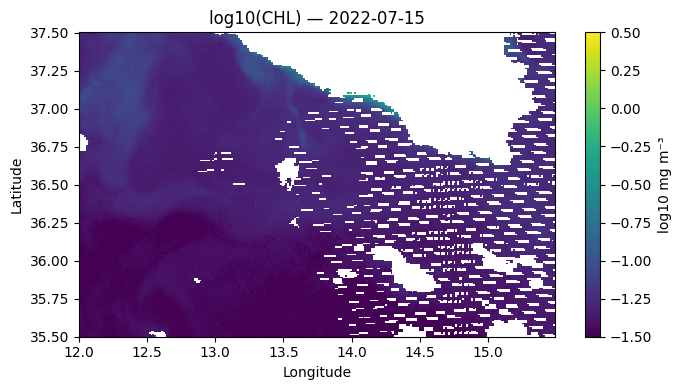

In [8]:
import numpy as np
import matplotlib.pyplot as plt

# pick a summer day likely to have decent coverage
day = ds.CHL.sel(time="2022-07-15", method="nearest")

fig, ax = plt.subplots(figsize=(7, 4))
im = ax.pcolormesh(
    day.longitude, day.latitude, np.log10(day),
    shading="auto", cmap="viridis", vmin=-1.5, vmax=0.5,
)
ax.set_title(f"log10(CHL) — {str(day.time.values)[:10]}")
ax.set_xlabel("Longitude"); ax.set_ylabel("Latitude")
plt.colorbar(im, ax=ax, label="log10 mg m⁻³")
plt.tight_layout()
plt.savefig(FIG_DIR / "01_chl_sample_day.png", dpi=150)
plt.show()

---
## Next: `02-Coverage-Atlas.ipynb`

Stage 2 turns the NaN pattern in this cube into a **per-month coverage diagnostic** that decides whether daily forecasting is viable, or whether the target must be a 3-day rolling composite. Do **not** skip it — winter convective blooms happen exactly when coverage is worst.